# 11 - Monthly and annual PM2.5 for 2026-2028: forecast and scenarios

**Question.** Where is Seoul's PM2.5 likely to be in the next three years, how likely is the city to meet the Korean annual standard of 15 ug/m3, and how many Bad days can be expected?

**What this is and is not.** The forecasts extrapolate the monthly behaviour of 2015-2025: its level, its season, its trend and the variation of its weather. They **do not anticipate shocks**: a new policy, an economic or emission change in Korea or China, a pandemic, a change of the measuring network or a weather year unlike those of 2015-2025. The data end in December 2025, so 2026 is forecast from that origin even though part of it has since been observed.

**Protocol.**
1. Five models on log monthly PM2.5 (city mean of the 25 urban stations): seasonal mean, ETS, damped trend, SARIMA, and a model on the weather-normalised series of notebook 09 (gradient boosting, refit at each origin with only earlier days).
2. Rolling origins every six months from January 2018 to July 2024; each origin forecasts up to 36 months, as far as the data reach. Scores: MASE (the error divided by the in-sample error of the seasonal naive forecast, so 1 means no better than repeating last year in sample) and the coverage of the 80% and 95% intervals.
3. One model is chosen with the rule below, fixed before any model was evaluated. The rule is printed from the code that applies it.
4. The chosen model gives the forecast for 2026-2028. Two scenarios, labelled as such, show what happens if the trend of the weather-normalised series continues or stops; they are assumptions, not forecasts.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from seoul_air import config, deweather, longterm as lt, trend
from seoul_air.metrics import is_bad
from seoul_air.report import load_key_figures, save_key_figures

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
config.FIGURES.mkdir(parents=True, exist_ok=True)
config.METRICS.mkdir(parents=True, exist_ok=True)

In [2]:
print("Selection rule (fixed in advance):")
print(lt.SELECTION_RULE)

Selection rule (fixed in advance):
1. Eligible: pooled coverage of the 80% interval over all origins and horizons between 0.70 and 0.90. 2. Among eligible models, the lowest mean MASE over all origins and horizons 1-36 months. 3. A model within 5% of that MASE that is simpler (order: seasonal mean, ETS, damped trend, SARIMA, deweathered (ML)) is preferred. 4. If no model is eligible, rule 2 and 3 apply to all models and the coverage problem is reported.


## 1. Monthly series

In [3]:
daily = pd.read_parquet(config.DATA_PROCESSED / "air_daily_2015_2025.parquet", columns=["date", "pm25"])
city = daily.groupby("date")["pm25"].mean()
city.index = pd.DatetimeIndex(city.index)
monthly = trend.monthly_means(city)
log_monthly = np.log(monthly)
weather_daily = pd.read_parquet(config.DATA_PROCESSED / "weather_daily_2015_2025.parquet")
weather_daily["date"] = pd.to_datetime(weather_daily["date"])
table = deweather.build_table(city, weather_daily)
chosen_09 = load_key_figures("09")["chosen_settings"]
DEWEATHER = {"small": {"max_iter": 200, "learning_rate": 0.05, "max_leaf_nodes": 15, "min_samples_leaf": 40},
             "default": {"max_iter": 400, "learning_rate": 0.05, "max_leaf_nodes": 31, "min_samples_leaf": 20},
             "large": {"max_iter": 800, "learning_rate": 0.03, "max_leaf_nodes": 63, "min_samples_leaf": 20}}[chosen_09]


def normalised_monthly_log(until):
    part = table[table.index < until.to_timestamp()]
    model = deweather.make_model(**DEWEATHER).fit(part[deweather.features(part)], part["pm25"])
    return np.log(trend.monthly_means(deweather.normalise(model, part, n_samples=50, seed=0)))


annual = city.groupby(city.index.year).mean()
bad = pd.Series(is_bad(city.to_numpy()), index=city.index).groupby(city.index.year).sum()
print("Months:", monthly.notna().sum(), "| from", monthly.index[0], "to", monthly.index[-1], "| missing:", int(monthly.isna().sum()))
print("Deweathering settings (notebook 09):", chosen_09)
print("Korean annual standard:", 15, "ug/m3 | a Bad-or-worse day: rounded daily mean above", 35, "ug/m3")
print(pd.DataFrame({"annual mean (ug/m3)": annual.round(2), "Bad-or-worse days": bad}).to_string())

Months: 132 | from 2015-01 to 2025-12 | missing: 0
Deweathering settings (notebook 09): small
Korean annual standard: 15 ug/m3 | a Bad-or-worse day: rounded daily mean above 35 ug/m3
      annual mean (ug/m3)  Bad-or-worse days
date                                        
2015                23.06                 44
2016                26.17                 72
2017                24.65                 64
2018                22.82                 61
2019                24.67                 64
2020                20.66                 46
2021                19.77                 35
2022                18.34                 31
2023                19.66                 35
2024                17.53                 24
2025                18.48                 32


**Interpretation.** The 132 monthly means have no gap. The annual mean fell from 26.17 ug/m3 in 2016 to 17.53 in 2024 and rose to 18.48 in 2025, and Bad-or-worse days from 72 to 24 and 32. The decline is not steady: it was fast in 2019-2022 and small since, which is what a forecast of the next three years has to weigh.

## 2. Rolling-origin evaluation

At each origin every model is fit on the months before it and simulates 2000 paths; the median is the point forecast and the 10th-90th and 2.5th-97.5th percentiles are the 80% and 95% intervals. The seasonal naive forecast (each month equal to the same month of the last training year) is shown as a reference only.

In [4]:
ORIGINS = pd.period_range("2018-01", "2024-07", freq="M")[::6]
N_PATHS = 2000
records, annual_records = [], []
for origin in ORIGINS:
    train = log_monthly[log_monthly.index < origin]
    test = monthly[monthly.index >= origin].iloc[:lt.HORIZON]
    h = len(test)
    scale = lt.seasonal_naive_scale(monthly[monthly.index < origin])
    normalised = normalised_monthly_log(origin)
    naive = np.tile(monthly[monthly.index < origin].iloc[-12:].to_numpy(), 3)[:h]
    for k in range(h):
        records.append({"origin": str(origin), "model": "seasonal naive (reference)", "horizon": k + 1,
                        "mase": abs(test.iloc[k] - naive[k]) / scale, "in_80": np.nan, "in_95": np.nan})
    for model in lt.MODELS:
        paths = lt.simulate(model, train, h, n=N_PATHS, seed=1, normalised_log=normalised)
        s = lt.summarise_paths(paths, test.index)
        for k in range(h):
            y = test.iloc[k]
            records.append({"origin": str(origin), "model": model, "horizon": k + 1,
                            "mase": abs(y - s["median"].iloc[k]) / scale,
                            "in_80": float(s["low_80"].iloc[k] <= y <= s["high_80"].iloc[k]),
                            "in_95": float(s["low_95"].iloc[k] <= y <= s["high_95"].iloc[k])})
        if origin.month == 1:
            simulated = lt.annual_from_monthly(np.exp(paths), test.index)
            for year, values in simulated.items():
                actual = annual.get(year, np.nan)
                low, mid, high = np.percentile(values, [10, 50, 90])
                annual_records.append({"origin": str(origin), "model": model, "years_ahead": year - origin.year + 1,
                                       "error": mid - actual, "in_80": float(low <= actual <= high)})
backtest = pd.DataFrame(records)
annual_backtest = pd.DataFrame(annual_records)
print("Origins:", len(ORIGINS), "| forecasts scored per model:", int((backtest["model"] == "ETS").sum()),
      "| paths per forecast:", N_PATHS, "| longest horizon:", lt.HORIZON, "months")
print("Intervals: 80% = 10th to 90th percentile, 95% =", 2.5, "to", 97.5, "percentile of the paths")
summary = backtest.groupby("model").agg(mase=("mase", "mean"), coverage_80=("in_80", "mean"),
                                         coverage_95=("in_95", "mean")).reset_index()
print(summary.round(3).to_string(index=False))
backtest["horizon band"] = pd.cut(backtest["horizon"], [0, 12, 24, 36], labels=["1-12", "13-24", "25-36"])
print()
print("MASE by horizon band (months):")
print(backtest.pivot_table(index="model", columns="horizon band", values="mase", observed=True).round(3).to_string())
print()
print("Coverage of the 80% interval by horizon band:")
print(backtest.pivot_table(index="model", columns="horizon band", values="in_80", observed=True).round(3).to_string())

Origins: 14 | forecasts scored per model: 468 | paths per forecast: 2000 | longest horizon: 36 months
Intervals: 80% = 10th to 90th percentile, 95% = 2.5 to 97.5 percentile of the paths
                     model  mase  coverage_80  coverage_95
                       ETS 0.663        0.835        0.936
                    SARIMA 0.700        0.844        0.951
              damped trend 0.671        0.788        0.910
          deweathered (ML) 0.710        0.810        0.904
             seasonal mean 0.805        0.556        0.816
seasonal naive (reference) 0.839          NaN          NaN

MASE by horizon band (months):
horizon band                 1-12  13-24  25-36
model                                          
ETS                         0.692  0.617  0.681
SARIMA                      0.705  0.671  0.726
damped trend                0.681  0.630  0.706
deweathered (ML)            0.727  0.654  0.754
seasonal mean               0.761  0.772  0.897
seasonal naive (reference)  0.851

Annual means forecast from January origins (2018-2024):
                              forecasts   mae  bias  coverage_80
model            years_ahead                                    
ETS              1                    7  1.57  0.16         0.86
                 2                    7  1.19  0.66         1.00
                 3                    6  1.84  1.78         1.00
SARIMA           1                    7  1.81  0.88         0.86
                 2                    7  1.58  1.05         0.71
                 3                    6  2.70  2.10         0.67
damped trend     1                    7  1.72  0.44         0.71
                 2                    7  1.28  0.97         0.86
                 3                    6  2.15  2.15         0.83
deweathered (ML) 1                    7  2.31  1.56         0.57
                 2                    7  2.04  1.95         0.86
                 3                    6  3.31  3.31         0.83
seasonal mean    1                

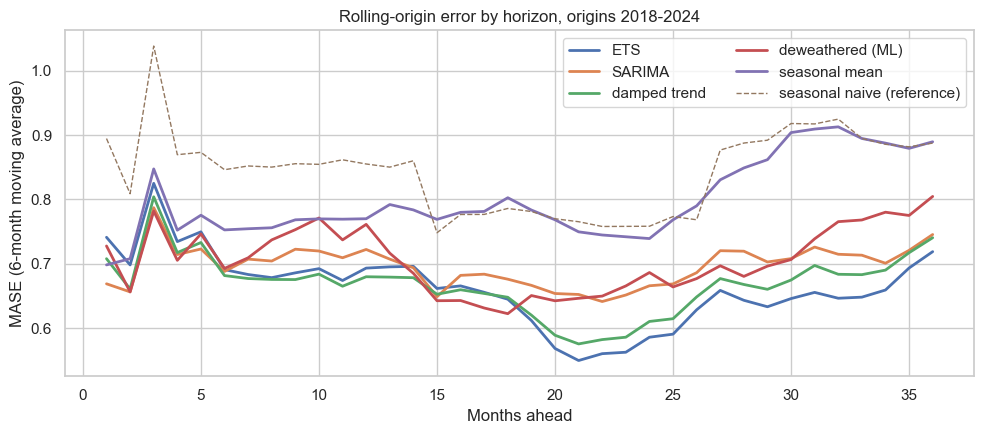

In [5]:
print("Annual means forecast from January origins (2018-2024):")
annual_summary = annual_backtest.groupby(["model", "years_ahead"]).agg(
    forecasts=("error", "size"), mae=("error", lambda e: e.abs().mean()), bias=("error", "mean"),
    coverage_80=("in_80", "mean"))
print(annual_summary.round(2).to_string())

fig, ax = plt.subplots(figsize=(10, 4.5))
curve = backtest.groupby(["model", "horizon"])["mase"].mean().unstack("model").rolling(6, min_periods=1).mean()
for model in curve.columns:
    ax.plot(curve.index, curve[model], lw=2 if model != "seasonal naive (reference)" else 1,
            ls="-" if model != "seasonal naive (reference)" else "--", label=model)
ax.set_xlabel("Months ahead")
ax.set_ylabel("MASE (6-month moving average)")
ax.set_title("Rolling-origin error by horizon, origins 2018-2024")
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(config.FIGURES / "11_backtest_mase.png", dpi=150)
plt.show()

**Interpretation.** Over 14 origins and 468 monthly forecasts per model, ETS has the lowest MASE (0.663), followed by the damped trend (0.671), SARIMA (0.700) and the model on the weather-normalised series (0.710); all beat the seasonal naive reference (0.839) and the seasonal mean (0.805). The differences between the four best models are small compared with the spread of errors between origins. The intervals of ETS, SARIMA, the damped trend and the deweathered model are close to their nominal level (80% coverage between 0.788 and 0.844); those of the seasonal mean are far too narrow (0.556), because they ignore the change of level. Removing the weather does not make the series easier to extrapolate: the weather adds month-to-month noise, but the hard part three years ahead is the level, and the weather-normalised level carries the same uncertainty. For annual means, ETS misses by 1.57, 1.19 and 1.84 ug/m3 one, two and three years ahead; its bias at three years (+1.78) shows that a model without a trend forecast too high while PM2.5 was falling, a warning for the central forecast below.

## 3. Choice of model

In [6]:
chosen, eligible = lt.choose(summary[summary["model"].isin(lt.MODELS)])
print("Chosen model:", chosen, "| chosen among eligible models:", eligible)
best = summary[summary["model"].isin(lt.MODELS)].sort_values("mase")
print("Lowest MASE:", best.iloc[0]["model"], round(best.iloc[0]["mase"], 3),
      "| chosen model MASE:", round(summary.set_index("model").loc[chosen, "mase"], 3))

Chosen model: ETS | chosen among eligible models: True
Lowest MASE: ETS 0.663 | chosen model MASE: 0.663


**Interpretation.** The rule chooses ETS: it is eligible (coverage 0.835) and has the lowest MASE; the damped trend is within 5% of it but is not simpler, so the rule keeps ETS. ETS has a level and a season but no trend: it projects the recent level forward, with uncertainty that grows with the horizon.

## 4. From monthly means to Bad days

A Bad day (daily mean above 35 ug/m3 after rounding) depends on how the days of a month spread around its mean. A simulated month borrows the daily shape (each day divided by the monthly mean) of a random month of the same calendar month in 2015-2025, scaled to the simulated mean. The check below applies the method to each past year with its real monthly means and the shapes of the other years only.

In [7]:
rng = np.random.default_rng(3)
check = []
for year in range(2015, 2026):
    profiles = lt.daily_profiles(city[city.index.year != year])
    months = monthly[monthly.index.year == year]
    values = np.repeat(months.to_numpy()[None, :], 1000, axis=0)
    simulated = lt.bad_days(values, months.index.month, profiles, rng).sum(axis=1)
    low, mid, high = np.percentile(simulated, [10, 50, 90])
    check.append({"year": year, "observed": int(bad[year]), "expected_median": mid, "low_80": low, "high_80": high,
                  "inside_80": low <= bad[year] <= high})
check = pd.DataFrame(check).set_index("year")
print(check.to_string())
print("Years inside the 80% range:", int(check["inside_80"].sum()), "of", len(check),
      "| mean of expected minus observed:", round((check["expected_median"] - check["observed"]).mean(), 1))

      observed  expected_median  low_80  high_80  inside_80
year                                                       
2015        44             53.0    48.0     59.0      False
2016        72             79.0    72.0     86.0       True
2017        64             69.0    63.0     75.0       True
2018        61             58.0    52.0     63.0       True
2019        64             69.0    63.0     75.0       True
2020        46             39.0    34.9     44.0      False
2021        35             39.0    33.0     44.0       True
2022        31             28.0    23.0     33.0       True
2023        35             34.0    29.0     38.0       True
2024        24             20.0    16.0     25.0       True
2025        32             31.0    26.0     35.0       True
Years inside the 80% range: 9 of 11 | mean of expected minus observed: 1.0


**Interpretation.** With the real monthly means of a year and the daily shapes of the other years, the method places the observed Bad days inside its 80% range in 9 of 11 years, and on average it expects 1.0 day more than observed. The two misses are 2015 (expected 53, observed 44) and 2020 (expected 39, observed 46). The method is good enough to translate monthly forecasts into an expected number of Bad days, with a range of several days either way.

## 5. Forecast for 2026-2028 (chosen model)

In [8]:
N_FINAL = 4000
future = lt.month_index("2026-01", lt.HORIZON)
normalised_all = normalised_monthly_log(pd.Period("2026-01", "M"))
profiles_all = lt.daily_profiles(city)
paths = {model: lt.simulate(model, log_monthly, lt.HORIZON, n=N_FINAL, seed=7, normalised_log=normalised_all)
         for model in lt.MODELS}


def describe(log_paths, label, seed):
    values = np.exp(log_paths)
    rows = []
    bad_paths = lt.bad_days(values, future.month, profiles_all, np.random.default_rng(seed))
    for year, annual_values in lt.annual_from_monthly(values, future).items():
        cols = future.year == year
        days = bad_paths[:, cols].sum(axis=1)
        rows.append({"series": label, "year": year,
                     "annual_median": np.median(annual_values),
                     "annual_low_80": np.percentile(annual_values, 10), "annual_high_80": np.percentile(annual_values, 90),
                     "p_meets_15": lt.meets_standard(annual_values),
                     "bad_days_median": np.median(days), "bad_days_low_80": np.percentile(days, 10),
                     "bad_days_high_80": np.percentile(days, 90)})
    return rows


forecast_rows = describe(paths[chosen], f"forecast: {chosen}", seed=11)
print(pd.DataFrame(forecast_rows).set_index(["series", "year"]).round(2).to_string())
print()
print("Median annual mean of every model (for comparison; only the chosen model is the forecast):")
print(pd.DataFrame({model: {year: np.median(v) for year, v in lt.annual_from_monthly(np.exp(p), future).items()}
                    for model, p in paths.items()}).round(2).to_string())

                    annual_median  annual_low_80  annual_high_80  p_meets_15  bad_days_median  bad_days_low_80  bad_days_high_80
series        year                                                                                                              
forecast: ETS 2026          17.43           15.6           19.54        0.09             24.0             14.0              36.0
              2027          17.46           15.0           20.30        0.16             23.0             12.0              40.0
              2028          17.46           14.5           21.01        0.21             24.0             10.0              44.0

Median annual mean of every model (for comparison; only the chosen model is the forecast):
      seasonal mean    ETS  damped trend  SARIMA  deweathered (ML)
2026          18.57  17.43         17.57   17.10             17.96
2027          18.54  17.46         17.60   16.34             17.98
2028          18.55  17.46         17.60   15.77             1

**Interpretation.** The ETS forecast keeps the annual mean near 17.4 ug/m3 in 2026-2028 (median 17.43, 17.46 and 17.46), with an 80% interval that widens from 15.6-19.54 in 2026 to 14.5-21.01 in 2028. The chance of an annual mean that rounds to 15 or less is 0.09 in 2026, 0.16 in 2027 and 0.21 in 2028; it grows only because the uncertainty grows, not because the forecast falls. The median number of Bad-or-worse days is 24, 23 and 24 a year, with 80% ranges from 14-36 in 2026 to 10-44 in 2028. The other models give medians from 15.77 (SARIMA, which extends a drift) to 18.57 (seasonal mean) in 2028, a reminder that the choice of model, not only the randomness of the weather, sets the outlook.

## 6. Scenarios (assumptions, not forecasts)

Both scenarios start from the weather-normalised level of 2025 and add the weather of a random year of 2015-2025.
- **Scenario A, decline continues**: the weather-normalised series keeps changing at its 2015-2025 rate, with the uncertainty of that rate (12-month block bootstrap of the Theil-Sen slope of the deseasonalised log series).
- **Scenario B, decline stalls**: the weather-normalised level stays at its 2025 value.

In [9]:
anomalies = log_monthly - normalised_all
deseasonalised = trend.deseasonalise(normalised_all).dropna()
t = trend.years_since_start(deseasonalised.index)
slope = trend.theil_sen(t, deseasonalised.to_numpy())[0]
slope_draws = trend.block_bootstrap_slopes(t, deseasonalised.to_numpy(), block=12, n_boot=2000, seed=0)
print("Slope uncertainty: block bootstrap with blocks of", 12, "months")
print("Weather-normalised trend, log units per year:", round(slope, 4), "| 95% interval",
      np.round(np.percentile(slope_draws, [2.5, 97.5]), 4), "| as % per year:", round(100 * (np.exp(slope) - 1), 2))
scenario_paths = {
    "scenario A: decline continues": lt.scenario_paths(normalised_all, anomalies, slope_draws, n=N_FINAL, seed=21),
    "scenario B: decline stalls": lt.scenario_paths(normalised_all, anomalies, [0.0], n=N_FINAL, seed=22),
}
rows = list(forecast_rows)
for i, (label, p) in enumerate(scenario_paths.items()):
    rows += describe(p, label, seed=31 + i)
outlook = pd.DataFrame(rows).set_index(["series", "year"])
print(outlook.round(2).to_string())

Slope uncertainty: block bootstrap with blocks of 12 months
Weather-normalised trend, log units per year: -0.0375 | 95% interval [-0.0452 -0.0299] | as % per year: -3.68


                                    annual_median  annual_low_80  annual_high_80  p_meets_15  bad_days_median  bad_days_low_80  bad_days_high_80
series                        year                                                                                                              
forecast: ETS                 2026          17.43          15.60           19.54        0.09             24.0             14.0              36.0
                              2027          17.46          15.00           20.30        0.16             23.0             12.0              40.0
                              2028          17.46          14.50           21.01        0.21             24.0             10.0              44.0
scenario A: decline continues 2026          18.15          17.71           18.89        0.00             29.0             22.0              36.0
                              2027          17.46          16.96           18.27        0.00             26.0             19.0    

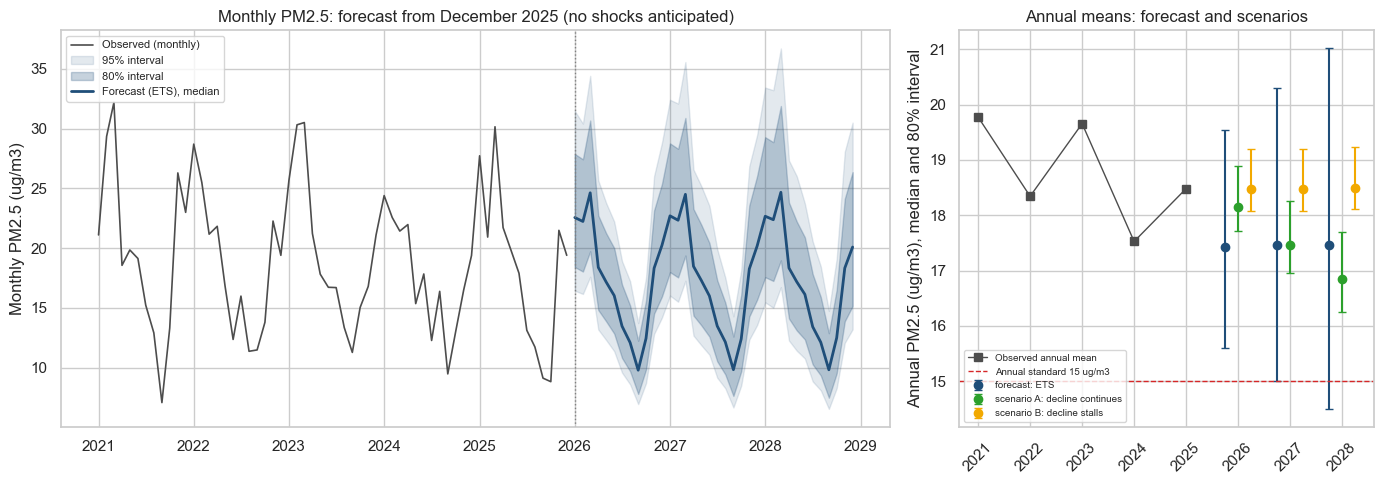

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2, 1]})
ax = axes[0]
history = monthly.loc["2021-01":]
ax.plot(history.index.to_timestamp(), history, color="0.3", lw=1.2, label="Observed (monthly)")
band = lt.summarise_paths(paths[chosen], future)
x = future.to_timestamp()
ax.fill_between(x, band["low_95"], band["high_95"], color="#1f4e79", alpha=0.12, label="95% interval")
ax.fill_between(x, band["low_80"], band["high_80"], color="#1f4e79", alpha=0.25, label="80% interval")
ax.plot(x, band["median"], color="#1f4e79", lw=2, label=f"Forecast ({chosen}), median")
ax.axvline(pd.Timestamp("2026-01-01"), color="0.5", ls=":", lw=1)
ax.set_ylabel("Monthly PM2.5 (ug/m3)")
ax.set_title("Monthly PM2.5: forecast from December 2025 (no shocks anticipated)")
ax.legend(loc="upper left", fontsize=8)
ax = axes[1]
years = sorted({y for _, y in outlook.index})
colors = {"forecast": "#1f4e79", "scenario A": "#2ca02c", "scenario B": "#f2a900"}
for i, series in enumerate(outlook.index.get_level_values(0).unique()):
    part = outlook.loc[series]
    color = colors[series.split(":")[0]]
    xs = np.array(years) + (i - 1) * 0.25
    ax.errorbar(xs, part["annual_median"], yerr=[part["annual_median"] - part["annual_low_80"], part["annual_high_80"] - part["annual_median"]],
                fmt="o", color=color, capsize=3, label=series)
ax.plot(annual.index[-5:], annual.iloc[-5:], color="0.3", marker="s", lw=1, label="Observed annual mean")
ax.axhline(15, color="#d62728", ls="--", lw=1, label="Annual standard 15 ug/m3")
ax.set_xticks(list(annual.index[-5:]) + years)
ax.tick_params(axis="x", rotation=45)
ax.set_ylabel("Annual PM2.5 (ug/m3), median and 80% interval")
ax.set_title("Annual means: forecast and scenarios")
ax.legend(fontsize=7, loc="lower left")
fig.tight_layout()
fig.savefig(config.FIGURES / "11_outlook.png", dpi=150)
plt.show()

**Interpretation.** The weather-normalised series fell by 3.68% a year in 2015-2025. If that continues (scenario A), the annual median falls from 18.15 ug/m3 in 2026 to 16.84 in 2028, and Bad days from 29 to 23 a year; the chance of meeting 15 ug/m3 stays at most 0.01, because from the weather-normalised level of 2025 (the 18.48 of scenario B) more than three years at that rate are needed to reach 15. If the decline stops (scenario B), the annual median stays at 18.48-18.49 with 30-31 Bad days a year and essentially no chance of meeting the standard. The scenario intervals are narrower than the forecast's because they only carry the weather and the uncertainty of the slope; they are conditional statements, not more confident forecasts. Under all three, meeting the annual standard by 2028 needs a faster decline than any seen in the weather-normalised series of 2015-2025, or a run of unusually favourable weather.

## 7. Key figures

In [11]:
save_key_figures("11", {
    "selection_rule": lt.SELECTION_RULE,
    "chosen_model": chosen,
    "chosen_among_eligible": eligible,
    "backtest": summary[summary["model"].isin(lt.MODELS)].set_index("model").to_dict(orient="index"),
    "seasonal_naive_mase": float(summary.set_index("model").loc["seasonal naive (reference)", "mase"]),
    "annual_backtest": {f"{m} | {y}": row.to_dict() for (m, y), row in annual_summary.iterrows()},
    "origins": [str(o) for o in ORIGINS],
    "bad_days_check_inside_80": int(check["inside_80"].sum()),
    "outlook": {f"{series} | {year}": row.to_dict() for (series, year), row in outlook.iterrows()},
    "normalised_slope_pct_per_year": 100 * (np.exp(slope) - 1),
})
print((config.METRICS / "11_key_figures.json").read_text()[:1000])

{
  "annual_backtest": {
    "ETS | 1": {
      "bias": 0.16182495142780645,
      "coverage_80": 0.8571428571428571,
      "forecasts": 7.0,
      "mae": 1.5720277475156215
    },
    "ETS | 2": {
      "bias": 0.6555200891506777,
      "coverage_80": 1.0,
      "forecasts": 7.0,
      "mae": 1.18996290384892
    },
    "ETS | 3": {
      "bias": 1.7758937343905323,
      "coverage_80": 1.0,
      "forecasts": 6.0,
      "mae": 1.8440872986457038
    },
    "SARIMA | 1": {
      "bias": 0.8791828096465615,
      "coverage_80": 0.8571428571428571,
      "forecasts": 7.0,
      "mae": 1.814943187782087
    },
    "SARIMA | 2": {
      "bias": 1.0546889781800266,
      "coverage_80": 0.7142857142857143,
      "forecasts": 7.0,
      "mae": 1.5759405639422386
    },
    "SARIMA | 3": {
      "bias": 2.104566529584543,
      "coverage_80": 0.6666666666666666,
      "forecasts": 6.0,
      "mae": 2.7047158108217637
    },
    "damped trend | 1": {
      "bias": 0.4393538317119443,
      "co

## Conclusion

- **Method**: five models were compared on 14 rolling origins up to 36 months ahead; the rule fixed in advance chose ETS (MASE 0.663, 80% coverage 0.835). The model on the weather-normalised series (0.710) did not improve the forecast.
- **Forecast**: annual PM2.5 around 17.4 ug/m3 in 2026-2028 (80% interval 14.5-21.01 in 2028), with 23-24 Bad-or-worse days a year as the median.
- **Annual standard of 15 ug/m3**: chance 0.09 in 2026, 0.16 in 2027 and 0.21 in 2028 under the forecast; at most 0.01 under the scenario in which the 2015-2025 decline continues, because the starting level is too high for three years at that rate.
- **Caution**: ETS forecast too high three years ahead while PM2.5 was falling (bias +1.78 ug/m3 in the evaluation). If the decline resumes, the outcome will lie below the central forecast; if it stalls, near scenario B.

**What these numbers cannot do**: they extend 2015-2025. A new policy, economic or emission changes in Korea or China, a pandemic, changes of the monitoring network, large dust or wildfire events beyond those of 2015-2025, or a new kind of weather year would move PM2.5 outside these ranges. They describe what the past implies, not what will happen.